# How to create a project

This tutorial demonstrates how to create a project.

## What is a project?

A project is a speos simulation container that includes parts, material properties, sensor,
sources and simulations.

In this tutorial you will learn how to create a project from scratch or from a pre-defined .speos
file.

## Prerequisites

### Perform imports

In [1]:
import os
from pathlib import Path

from ansys.speos.core import Project, Speos
from ansys.speos.core.generic.version_checker import server_version_checker
from ansys.speos.core.kernel.client import (
    default_docker_channel,
)
from ansys.speos.core.launcher import launch_local_speos_rpc_server
from ansys.speos.core.sensor import SensorIrradiance
from ansys.speos.core.simulation import SimulationDirect
from ansys.speos.core.source import SourceLuminaire, SourceSurface


### Define constants

The constants help ensure consistency and avoid repetition throughout the example.

In [2]:
HOSTNAME = "localhost"
GRPC_PORT = 50098  # Be sure the Speos GRPC Server has been started on this port.
USE_DOCKER = True  # Set to False if you're running this example locally as a Notebook.

## Model Setup

### Load assets
The assets used to run this example are available in the
[PySpeos repository](https://github.com/ansys/pyspeos/) on GitHub.

> **Note:** Make sure you
> have downloaded simulation assets and set ``assets_data_path``
> to point to the assets folder.

In [3]:
if USE_DOCKER:  # Running on the remote server.
    assets_data_path = Path("/app") / "assets"
else:
    assets_data_path = Path("/path/to/your/download/assets/directory")

### Start/Connect to Speos RPC Server
This Python client connects to a server where the Speos engine
is running as a service. In this example, the server and
client are the same machine. the launch_local_speos_rpc_method can
be used to start a local instance of the service.

In [4]:
if USE_DOCKER:
    speos = Speos(channel=default_docker_channel())
else:
    speos = launch_local_speos_rpc_server(port=GRPC_PORT)

/home/runner/work/pyspeos/pyspeos/.venv/lib/python3.14/site-packages/ansys/tools/common/cyberchannel.py:201: UserWarning: Starting gRPC client without TLS on localhost:50098. This is INSECURE. Consider using a secure connection.
  warn(f"Starting gRPC client without TLS on {target}. This is INSECURE. Consider using a secure connection.")


## New empty project

An empty project can be created by only passing speos rpc server to
the Project class.

In [5]:
p = Project(speos=speos)
print(p)

{
    "name": "",
    "description": "",
    "metadata": {},
    "part_guid": "",
    "sub_scene_anchor_axis_system": [],
    "sources": [],
    "sensors": [],
    "simulations": [],
    "materials": [],
    "scenes": [],
    "textures_3d": []
}


### Create features
The Project class has a multitude of method to create Speos features.
each create methedo takes the name and the Feature type as arguments
and returns the created Feature
#### Source

In [6]:
source1 = p.create_source(name="Source.1", feature_type=SourceLuminaire)
source1.intensity_file_uri = assets_data_path / "IES_C_DETECTOR.ies"
source1.commit()

#### Sensor

In [7]:
sensor1 = p.create_sensor(name="Sensor.1")
sensor1.commit()

#### Optical property

In [8]:
opt_prop1 = p.create_optical_property(name="Material.1")
opt_prop1.commit()

## Read Project

User can read the content of a project via simply printing the project

In [9]:
print(p)

{
    "sources": [
        {
            "name": "Source.1",
            "metadata": {
                "UniqueId": "9245fe97-d2f3-44e4-99da-ee2dfcc894f7"
            },
            "source_guid": "c884585b-855d-44e4-b8f9-981beed68126",
            "display_name": "",
            "description": "",
            "source": {
                "name": "Source.1",
                "luminaire": {
                    "flux_from_intensity_file": {},
                    "intensity_file_uri": "/app/assets/IES_C_DETECTOR.ies",
                    "spectrum_guid": "cd4acb3c-302f-4afc-8379-a7564e25e1c2",
                    "spectrum": {
                        "name": "Source.1.Spectrum",
                        "predefined": {
                            "incandescent": {}
                        },
                        "description": "",
                        "metadata": {}
                    },
                    "axis_system": [
                        0.0,
                        0.0,
    

Or, user can use the find_key method to read a specific feature:

In [10]:
for it in p.find_key(key="monochromatic"):
    print(it)

## Find a feature inside a project

### Use find method with an exact name

If no feature is found, an empty list is returned.

In [11]:
features = p.find(name="UnexistingName")
print(features)

[]


In [12]:
features = p.find(name="Sensor.1")
print(features[0])

{
    "name": "Sensor.1",
    "metadata": {
        "UniqueId": "88efe0e8-8773-4c3d-9ef9-9f344bcb2c40"
    },
    "sensor_guid": "def17b67-ac95-4819-9a2e-19a6bdd6a120",
    "display_name": "",
    "description": "",
    "result_file_name": "",
    "sensor": {
        "name": "Sensor.1",
        "irradiance": {
            "mode_photometric": {},
            "integration_type": "INTEGRATION_TYPE_PLANAR",
            "dimensions": {
                "x_start": -50.0,
                "x_end": 50.0,
                "x_sampling": 100,
                "y_start": -50.0,
                "y_end": 50.0,
                "y_sampling": 100
            },
            "axis_system": [
                0.0,
                0.0,
                0.0,
                1.0,
                0.0,
                0.0,
                0.0,
                1.0,
                0.0,
                0.0,
                0.0,
                1.0
            ],
            "layer_type_none": {},
            "ray_file

### Use find method with feature type

Here a wrong type is given: no source is called Sensor.1 in the project

In [13]:
features = p.find(name="Sensor.1", feature_type=SourceLuminaire)
print(features)

[]


In [14]:
features = p.find(name="Sensor.1", feature_type=SensorIrradiance)
print(features[0])

{
    "name": "Sensor.1",
    "metadata": {
        "UniqueId": "88efe0e8-8773-4c3d-9ef9-9f344bcb2c40"
    },
    "sensor_guid": "def17b67-ac95-4819-9a2e-19a6bdd6a120",
    "display_name": "",
    "description": "",
    "result_file_name": "",
    "sensor": {
        "name": "Sensor.1",
        "irradiance": {
            "mode_photometric": {},
            "integration_type": "INTEGRATION_TYPE_PLANAR",
            "dimensions": {
                "x_start": -50.0,
                "x_end": 50.0,
                "x_sampling": 100,
                "y_start": -50.0,
                "y_end": 50.0,
                "y_sampling": 100
            },
            "axis_system": [
                0.0,
                0.0,
                0.0,
                1.0,
                0.0,
                0.0,
                0.0,
                1.0,
                0.0,
                0.0,
                0.0,
                1.0
            ],
            "layer_type_none": {},
            "ray_file

### Use find method with approximation name with regex

find a feature with name starting with Mat

In [15]:
features = p.find(name="Mat.*", name_regex=True)
for feat in features:
    print(str(type(feat)) + " : name=" + feat._name)

<class 'ansys.speos.core.opt_prop.OptProp'> : name=Material.1


find all features without defining any name

In [16]:
features = p.find(name=".*", name_regex=True)
for feat in features:
    print(str(type(feat)) + " : name=" + feat._name)

<class 'ansys.speos.core.source.SourceLuminaire'> : name=Source.1
<class 'ansys.speos.core.sensor.SensorIrradiance'> : name=Sensor.1
<class 'ansys.speos.core.opt_prop.OptProp'> : name=Material.1


## Delete

This erases the scene content in server database.

This deletes also each feature of the project

In [17]:
p.delete()
print(p)

{
    "name": "",
    "description": "",
    "metadata": {},
    "part_guid": "",
    "sub_scene_anchor_axis_system": [],
    "sources": [],
    "sensors": [],
    "simulations": [],
    "materials": [],
    "scenes": [],
    "textures_3d": []
}


As the features were deleted just above -> this returns an empty vector

In [18]:
print(p.find(name="Sensor.1"))

[]


## Create project from pre-defined speos project

Via passing the .speos/.sv5 file path to the Project class.

In [19]:
p2 = Project(
    speos=speos,
    path=str(assets_data_path / "LG_50M_Colorimetric_short.sv5" / "LG_50M_Colorimetric_short.sv5"),
)
print(p2)

{
    "name": "LG_50M_Colorimetric_short",
    "description": "From Speos file: /app/assets/LG_50M_Colorimetric_short.sv5/LG_50M_Colorimetric_short.sv5",
    "part_guid": "5c0022d4-91d4-4952-9698-306ae779f2d4",
    "sources": [
        {
            "name": "Dom Source 2 (0) in SOURCE2",
            "metadata": {
                "UniqueId": "489ad7cb-ad07-4f18-ad31-cb53df3a9e23"
            },
            "source_guid": "ff88f72c-fd07-41e6-a80f-a4e158775434",
            "display_name": "",
            "description": "",
            "source": {
                "name": "Dom Source 2 (0) in SOURCE2",
                "surface": {
                    "radiant_flux": {
                        "radiant_value": 6.590041607465698
                    },
                    "intensity_guid": "48778680-c003-493a-adc3-1383dca94f42",
                    "exitance_constant": {
                        "geo_paths": [
                            {
                                "geo_path": "Solid Body

## Preview the part information

User can check the project part using preview method.

In [20]:
p2.preview()

EmbeddableWidget(value='<iframe srcdoc="<!DOCTYPE html>\n<html>\n  <head>\n    <meta http-equiv=&quot;Content-…

use find_key method to find specific information

In [21]:
for it in p2.find_key(key="surface"):
    print(it)

(".sources[.name='Dom Source 2 (0) in SOURCE2'].source.surface", {'radiant_flux': {'radiant_value': 6.590041607465698}, 'intensity_guid': '48778680-c003-493a-adc3-1383dca94f42', 'exitance_constant': {'geo_paths': [{'geo_path': 'Solid Body in SOURCE2:2920204960/Face in SOURCE2:222', 'reverse_normal': False}]}, 'spectrum_guid': 'eed87596-21ce-4295-82c2-4d417e241684', 'intensity': {'cos': {'N': 1.0, 'total_angle': 180.0}, 'name': '', 'description': '', 'metadata': {}}, 'spectrum': {'library': {'file_uri': '/app/assets/LG_50M_Colorimetric_short.sv5/Red Spectrum.spectrum'}, 'name': '', 'description': '', 'metadata': {}}})
(".sources[.name='Surface Source (0) in SOURCE1'].source.surface", {'radiant_flux': {'radiant_value': 9.290411220389682}, 'intensity_guid': '75582ced-cd01-4d02-a042-fa80e43ab6f1', 'exitance_constant': {'geo_paths': [{'geo_path': 'Solid Body in SOURCE1:2494956811/Face in SOURCE1:187', 'reverse_normal': False}]}, 'spectrum_guid': '8d8152f2-e53d-43f5-bce3-224c19fe2237', 'inte

Use find method to retrieve feature:

e.g. surface source

In [22]:
features = p2.find(name=".*", name_regex=True, feature_type=SourceSurface)
print(features)
for feat in features:
    print(str(type(feat)) + " : name=" + feat._name)
src = features[1]

[<ansys.speos.core.source.SourceSurface object at 0x7f6b9cb39a90>, <ansys.speos.core.source.SourceSurface object at 0x7f6b9cb582d0>]
<class 'ansys.speos.core.source.SourceSurface'> : name=Dom Source 2 (0) in SOURCE2
<class 'ansys.speos.core.source.SourceSurface'> : name=Surface Source (0) in SOURCE1


modify the surface source, e.g. surface source wavelength:

In [23]:
src.spectrum.set_monochromatic().wavelength = 550
src.commit()

Retrieve a simulation feature:

In [24]:
features = p2.find(name=".*", name_regex=True, feature_type=SimulationDirect)
sim_feat = features[0]
print(sim_feat)

{
    "name": "ASSEMBLY1.DS (0)",
    "metadata": {
        "UniqueId": "20ee7878-101b-4246-bbdc-ade84640abc3"
    },
    "simulation_guid": "ba5ef39d-92ee-419f-b4d8-55f17ccaaf16",
    "sensor_paths": [
        "Dom Irradiance Sensor (0)"
    ],
    "source_paths": [
        "Dom Source 2 (0) in SOURCE2",
        "Surface Source (0) in SOURCE1"
    ],
    "geometries": {
        "geo_paths": []
    },
    "display_name": "",
    "description": "",
    "source_groups": [],
    "simulation": {
        "direct_mc_simulation_template": {
            "geom_distance_tolerance": 0.05,
            "max_impact": 100,
            "weight": {
                "minimum_energy_percentage": 0.005
            },
            "dispersion": true,
            "colorimetric_standard": "CIE_1931",
            "fast_transmission_gathering": false,
            "ambient_material_uri": "",
            "stop_condition_rays_number": "500000",
            "automatic_save_frequency": 60
        },
        "name": "

In [25]:
sim_feat.compute_CPU()

[upload_response {
  info {
    uri: "34be6a7c-08ad-472e-b4ed-d79e109053f7"
    file_name: "ASSEMBLY1.DS (0).Dom Irradiance Sensor (0).xmp"
    file_size: 1191537
  }
}
, upload_response {
  info {
    uri: "acf91e44-0953-46a3-989d-691eee16c956"
    file_name: "ASSEMBLY1.DS (0).html"
    file_size: 205824
  }
}
]

Preview simulation result

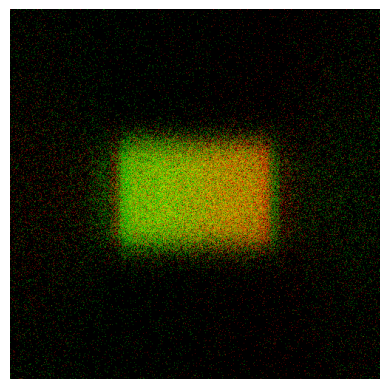

In [26]:
# Method available only on Windows OS or with Speos 2026 R1.2 or higher,
# which supports opening XMP results as images regardless of the OS.
if os.name == "nt" or server_version_checker.is_version_supported(2026, 1, 2):
    from ansys.speos.core.workflow.open_result import open_result_image

    open_result_image(
        simulation_feature=sim_feat,
        result_name="ASSEMBLY1.DS (0).Dom Irradiance Sensor (0).xmp",
    )

In [27]:
speos.close()

True